<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/general_relativity/gr_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*General Relativity* — `gr_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# GR Chapter 1 — Figures
**General Relativity · Ch 1: Geodesics in Spacetime**  
Tong lectures — SeoulTech PSE Lab

Figures produced:
- `gr_fig01_newton_vs_gr.png` — Newton vs GR: instantaneous vs causal propagation
- `gr_fig02_geodesic_sphere.png` — Great circles on S²
- `gr_fig03_equivalence_principle.png` — Elevator / free fall equivalence
- `gr_fig04_rindler.png` — Rindler wedge (Minkowski with hyperbolic trajectory)
- `gr_fig05_time_dilation.png` — Gravitational time dilation schematic
- `gr_fig06_effective_potential.png` — Schwarzschild effective potential Veff(r)
- `gr_fig07_perihelion.png` — Perihelion precession diagram
- `gr_fig08_light_bending.png` — Light deflection geometry

All figures use a dark background palette.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyBboxPatch
from mpl_toolkits.mplot3d import Axes3D
import os

os.makedirs('figures', exist_ok=True)

# ── Dark theme palette (matching gr_slides.css) ──
BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
GOLD    = '#d4a017'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

def dark_fig(w=8, h=5):
    fig, ax = plt.subplots(figsize=(w, h))
    fig.patch.set_facecolor(BG)
    ax.set_facecolor(BG)
    for spine in ax.spines.values():
        spine.set_color(BORDER)
    ax.tick_params(colors=MUTED)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
    ax.title.set_color(GOLD)
    return fig, ax

SAVE_KW = dict(dpi=150, bbox_inches='tight', facecolor=BG)
print('Setup complete. Dark palette loaded.')

Setup complete. Dark palette loaded.


## Fig 1 — Newton vs GR: Causal Propagation

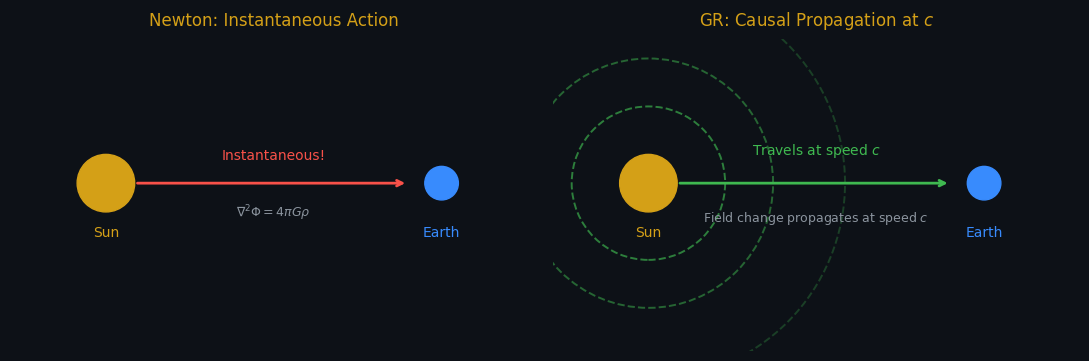

Fig 1 saved.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.patch.set_facecolor(BG)

titles = ['Newton: Instantaneous Action', 'GR: Causal Propagation at $c$']
colors_arr = [RED, GREEN]

for ax, title, col in zip(axes, titles, colors_arr):
    ax.set_facecolor(BG)
    ax.set_xlim(-0.5, 10.5)
    ax.set_ylim(-0.5, 6)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, color=GOLD, fontsize=12, pad=10)

    # Sun (left) and Earth (right)
    sun  = Circle((1.5, 3), 0.6, color=GOLD, zorder=5)
    earth = Circle((8.5, 3), 0.35, color=BLUE, zorder=5)
    ax.add_patch(sun)
    ax.add_patch(earth)
    ax.text(1.5, 1.9, 'Sun', color=GOLD, ha='center', fontsize=10)
    ax.text(8.5, 1.9, 'Earth', color=BLUE, ha='center', fontsize=10)

    if title.startswith('Newton'):
        # Instantaneous arrow — straight, red
        ax.annotate('', xy=(7.8, 3), xytext=(2.1, 3),
                    arrowprops=dict(arrowstyle='->', color=RED, lw=2.0))
        ax.text(5.0, 3.5, 'Instantaneous!', color=RED, ha='center', fontsize=10)
        ax.text(5.0, 2.3, r'$\nabla^2\Phi = 4\pi G\rho$', color=MUTED,
                ha='center', fontsize=9)
        # Explosion flash
        for angle in np.linspace(0, 2*np.pi, 8, endpoint=False):
            dx, dy = 0.5*np.cos(angle), 0.5*np.sin(angle)
            ax.annotate('', xy=(1.5+dx, 3+dy), xytext=(1.5, 3),
                        arrowprops=dict(arrowstyle='->', color=RED, lw=1.2))
    else:
        # Wavefronts — expanding circles in green
        for r in [1.0, 2.0, 3.5]:
            alpha = 0.8 - r*0.15
            circ = Circle((1.5, 3), r+0.6, fill=False, edgecolor=GREEN,
                          lw=1.4, alpha=max(alpha, 0.2), linestyle='--')
            ax.add_patch(circ)
        ax.annotate('', xy=(7.8, 3), xytext=(2.1, 3),
                    arrowprops=dict(arrowstyle='->', color=GREEN, lw=2.0))
        ax.text(5.0, 3.6, 'Travels at speed $c$', color=GREEN, ha='center', fontsize=10)
        ax.text(5.0, 2.2, 'Field change propagates at speed $c$', color=MUTED,
                ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('figures/gr_fig01_newton_vs_gr.png', **SAVE_KW)
plt.show()
print('Fig 1 saved.')

## Fig 2 — Great Circles on S²

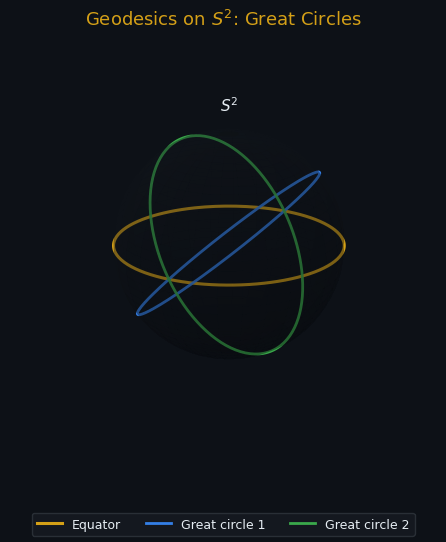

Fig 2 saved.


In [3]:
fig = plt.figure(figsize=(5.5, 5.5))
fig.patch.set_facecolor(BG)
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor(BG)

u = np.linspace(0, 2*np.pi, 60)
v = np.linspace(0, np.pi, 40)
xs = np.outer(np.cos(u), np.sin(v))
ys = np.outer(np.sin(u), np.sin(v))
zs = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_surface(xs, ys, zs, color=SURFACE, alpha=0.25, linewidth=0)

t = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(t), np.sin(t), np.zeros_like(t), color=GOLD, lw=2.2, label='Equator')
for angle, col, lbl in [(45, BLUE, 'Great circle 1'), (120, GREEN, 'Great circle 2')]:
    a = np.radians(angle)
    ax.plot(np.cos(t), np.sin(t)*np.cos(a), np.sin(t)*np.sin(a), color=col, lw=2.0, alpha=0.9, label=lbl)

ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_zlim(-1.1, 1.1)
ax.set_box_aspect([1,1,1])
ax.grid(False)
ax.set_axis_off()
ax.set_title('Geodesics on $S^2$: Great Circles', color=GOLD, fontsize=13, pad=8)
# Place S² label at top of sphere
ax.text(0, 0, 1.2, '$S^2$', color=TEXT, fontsize=11, ha='center')
# Tighten view
ax.view_init(elev=20, azim=30)

fig.subplots_adjust(top=0.93, bottom=0.12)
fig.legend(loc='lower center', ncol=3, facecolor=SURFACE, edgecolor=BORDER,
           labelcolor=TEXT, fontsize=9)

plt.savefig('figures/gr_fig02_geodesic_sphere.png', **SAVE_KW)
plt.show()
print('Fig 2 saved.')


## Fig 3 — Equivalence Principle

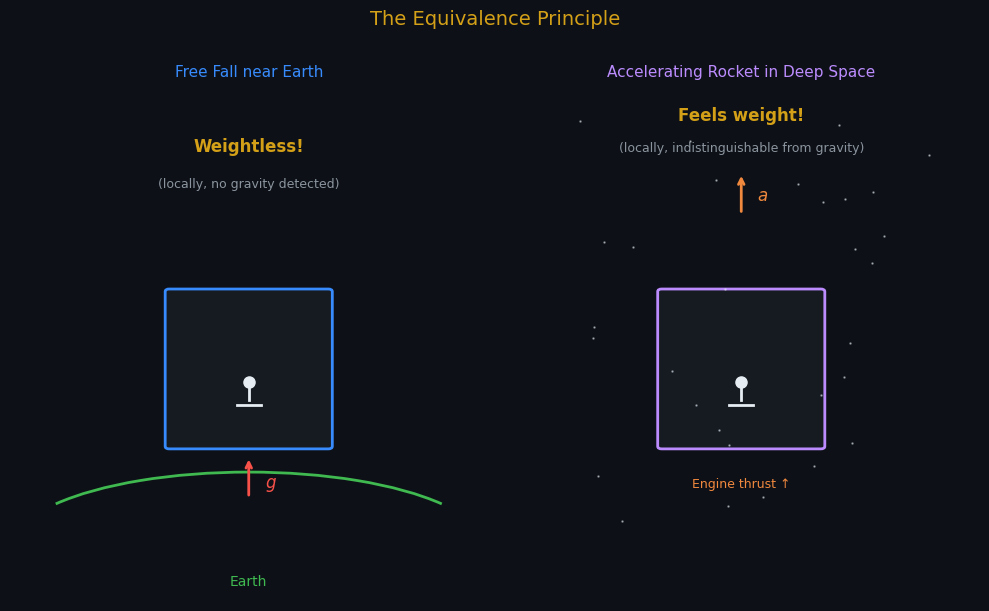

Fig 3 saved.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
fig.patch.set_facecolor(BG)
fig.suptitle('The Equivalence Principle', color=GOLD, fontsize=14, y=1.01)

def draw_elevator(ax, x0, y0, w=2.0, h=3.0, color=BLUE):
    rect = FancyBboxPatch((x0, y0), w, h, boxstyle='round,pad=0.05',
                          linewidth=2, edgecolor=color, facecolor=SURFACE)
    ax.add_patch(rect)
    px, py = x0 + w/2, y0 + 0.9
    ax.plot(px, py+0.35, 'o', color=TEXT, ms=8, zorder=6)
    ax.plot([px, px], [py, py+0.3], color=TEXT, lw=2, zorder=6)
    ax.plot([px-0.15, px+0.15], [py-0.1, py-0.1], color=TEXT, lw=2, zorder=6)

# Left: free fall
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-1.5, 8.5)
ax.axis('off')
ax.set_title('Free Fall near Earth', color=BLUE, fontsize=11)

earth_arc = Arc((2.5, -0.5), 6, 3, color=GREEN, lw=2, theta1=20, theta2=160)
ax.add_patch(earth_arc)
ax.text(2.5, -1.2, 'Earth', color=GREEN, ha='center', fontsize=10)

draw_elevator(ax, 1.5, 1.5, color=BLUE)  # box top at y=4.5

ax.annotate('', xy=(2.5, 1.3), xytext=(2.5, 0.5),
            arrowprops=dict(arrowstyle='->', color=RED, lw=2))
ax.text(2.7, 0.7, '$g$', color=RED, fontsize=12)

# Labels well above box top (4.5)
ax.text(2.5, 7.2, 'Weightless!', color=GOLD, ha='center', fontsize=12, fontweight='bold')
ax.text(2.5, 6.5, '(locally, no gravity detected)', color=MUTED, ha='center', fontsize=9)

# Right: rocket
ax = axes[1]
ax.set_facecolor(BG)
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-1.5, 8.5)
ax.axis('off')
ax.set_title('Accelerating Rocket in Deep Space', color=PURPLE, fontsize=11)

draw_elevator(ax, 1.5, 1.5, color=PURPLE)  # box top at y=4.5

rng = np.random.default_rng(42)
for _ in range(30):
    sx, sy = rng.uniform(0,5), rng.uniform(0,8)
    ax.plot(sx, sy, '.', color=TEXT, ms=1.5, alpha=0.5)

# Arrow above box, label to the right of arrow
ax.annotate('', xy=(2.5, 6.8), xytext=(2.5, 6.0),
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2))
ax.text(2.7, 6.25, '$a$', color=ORANGE, fontsize=12)

ax.text(2.5, 0.7, 'Engine thrust ↑', color=ORANGE, ha='center', fontsize=9)
ax.text(2.5, 7.8, 'Feels weight!', color=GOLD, ha='center', fontsize=12, fontweight='bold')
ax.text(2.5, 7.2, '(locally, indistinguishable from gravity)', color=MUTED, ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('figures/gr_fig03_equivalence_principle.png', **SAVE_KW)
plt.show()
print('Fig 3 saved.')


## Fig 4 — Rindler Wedge

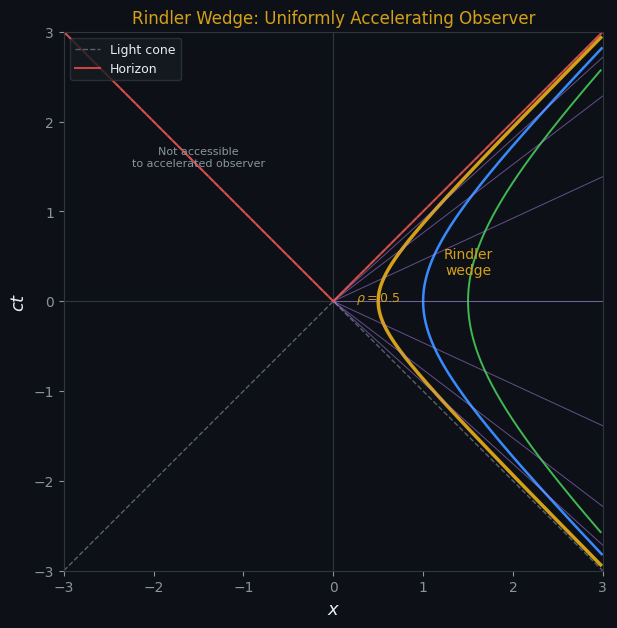

Fig 4 saved.


In [5]:
fig, ax = dark_fig(8, 7)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect('equal')
ax.set_xlabel('$x$', fontsize=13)
ax.set_ylabel('$ct$', fontsize=13)
ax.set_title('Rindler Wedge: Uniformly Accelerating Observer', fontsize=12)
ax.axhline(0, color=BORDER, lw=0.8)
ax.axvline(0, color=BORDER, lw=0.8)

# Light cone diagonals
ax.plot([-3, 3], [-3, 3], color=MUTED, lw=1.0, ls='--', alpha=0.6, label='Light cone')
ax.plot([-3, 3], [3, -3], color=MUTED, lw=1.0, ls='--', alpha=0.6)

# Hyperbolic trajectories (constant rho) — standard Rindler: x=ρ cosh τ, ct=ρ sinh τ
# Each curve satisfies x²-(ct)²=ρ², asymptotes coincide with ct=±x horizon
tau = np.linspace(-2.5, 2.5, 500)
for rho, col, lw in [(0.5, GOLD, 2.5), (1.0, BLUE, 1.8), (1.5, GREEN, 1.4)]:
    x_traj = rho * np.cosh(tau)
    ct_traj = rho * np.sinh(tau)
    mask = (np.abs(x_traj) < 3) & (np.abs(ct_traj) < 3)
    ax.plot(x_traj[mask], ct_traj[mask], color=col, lw=lw)
    if rho == 0.5:
        ix = np.argmin(x_traj[mask])
        ax.text(x_traj[mask][ix]-0.25, ct_traj[mask][ix], r'$\rho=0.5$',
                color=GOLD, fontsize=9)

# Constant tau lines (lines of simultaneity for Rindler observer)
for tau_val in np.linspace(-1.5, 1.5, 7):
    slope = np.tanh(tau_val)
    xs_line = np.linspace(0, 3, 50)
    ys_line = slope * xs_line
    mask = (np.abs(ys_line) < 3)
    ax.plot(xs_line[mask], ys_line[mask], color=PURPLE, lw=0.7, alpha=0.5)

# Horizon lines
ax.plot([0, 3], [0, 3], color=RED, lw=1.5, ls='-', alpha=0.8, label='Horizon')
ax.plot([0, -3], [0, 3], color=RED, lw=1.5, ls='-', alpha=0.8)

ax.text(1.5, 0.3, 'Rindler\nwedge', color=GOLD, fontsize=10, ha='center')
ax.text(-1.5, 1.5, 'Not accessible\nto accelerated observer', color=MUTED,
        fontsize=8, ha='center')

ax.legend(loc='upper left', facecolor=SURFACE, edgecolor=BORDER,
          labelcolor=TEXT, fontsize=9)

plt.savefig('figures/gr_fig04_rindler.png', **SAVE_KW)
plt.show()
print('Fig 4 saved.')

## Fig 5 — Gravitational Time Dilation

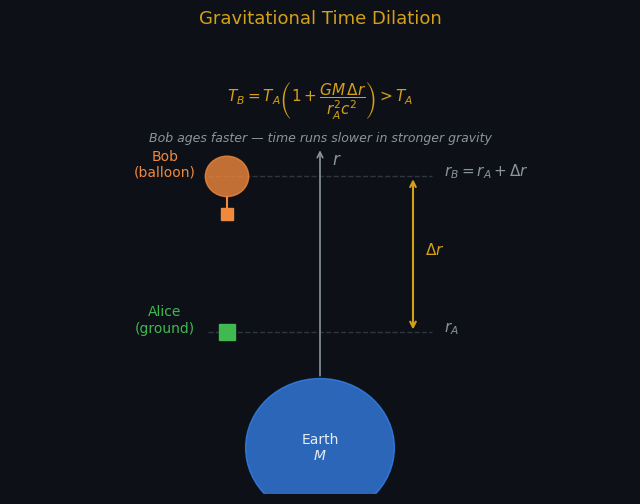

Fig 5 saved.


In [6]:
fig, ax = dark_fig(8, 6)
ax.set_xlim(0, 10)
ax.set_ylim(0, 8)
ax.axis('off')
ax.set_title('Gravitational Time Dilation', fontsize=13)

# Earth
earth = Circle((5, 0.8), 1.2, color=BLUE, alpha=0.7, zorder=4)
ax.add_patch(earth)
ax.text(5, 0.8, 'Earth\n$M$', color=TEXT, ha='center', va='center', fontsize=10, zorder=5)

# Ground level and balloon
r_A, r_B = 2.8, 5.5

# Radial axis
ax.annotate('', xy=(5, 6.0), xytext=(5, 2.0),
            arrowprops=dict(arrowstyle='->', color=MUTED, lw=1.2))
ax.text(5.2, 5.7, '$r$', color=MUTED, fontsize=12)

# Alice (ground)
ax.plot([3.2, 6.8], [r_A, r_A], color=BORDER, lw=1, ls='--')
ax.plot(3.5, r_A, 's', color=GREEN, ms=12, zorder=5)
ax.text(2.5, r_A, 'Alice\n(ground)', color=GREEN, ha='center', fontsize=10)
ax.text(7.0, r_A, r'$r_A$', color=MUTED, fontsize=11)

# Bob (balloon)
ax.plot([3.2, 6.8], [r_B, r_B], color=BORDER, lw=1, ls='--')
# Balloon
balloon = Circle((3.5, r_B), 0.35, color=ORANGE, alpha=0.8, zorder=5)
ax.add_patch(balloon)
ax.plot([3.5, 3.5], [r_B-0.35, r_B-0.55], color=ORANGE, lw=1.5)
ax.plot(3.5, r_B-0.65, 's', color=ORANGE, ms=8, zorder=5)
ax.text(2.5, r_B, 'Bob\n(balloon)', color=ORANGE, ha='center', fontsize=10)
ax.text(7.0, r_B, r'$r_B = r_A + \Delta r$', color=MUTED, fontsize=11)

# Δr brace
ax.annotate('', xy=(6.5, r_B), xytext=(6.5, r_A),
            arrowprops=dict(arrowstyle='<->', color=GOLD, lw=1.5))
ax.text(6.7, (r_A+r_B)/2, r'$\Delta r$', color=GOLD, fontsize=11)

# Time comparison text
ax.text(5, 6.8,
        r'$T_B = T_A\left(1 + \dfrac{GM\,\Delta r}{r_A^2 c^2}\right) > T_A$',
        color=GOLD, ha='center', fontsize=11)
ax.text(5, 6.1, 'Bob ages faster — time runs slower in stronger gravity',
        color=MUTED, ha='center', fontsize=9, style='italic')

plt.savefig('figures/gr_fig05_time_dilation.png', **SAVE_KW)
plt.show()
print('Fig 5 saved.')

## Fig 6 — Schwarzschild Effective Potential

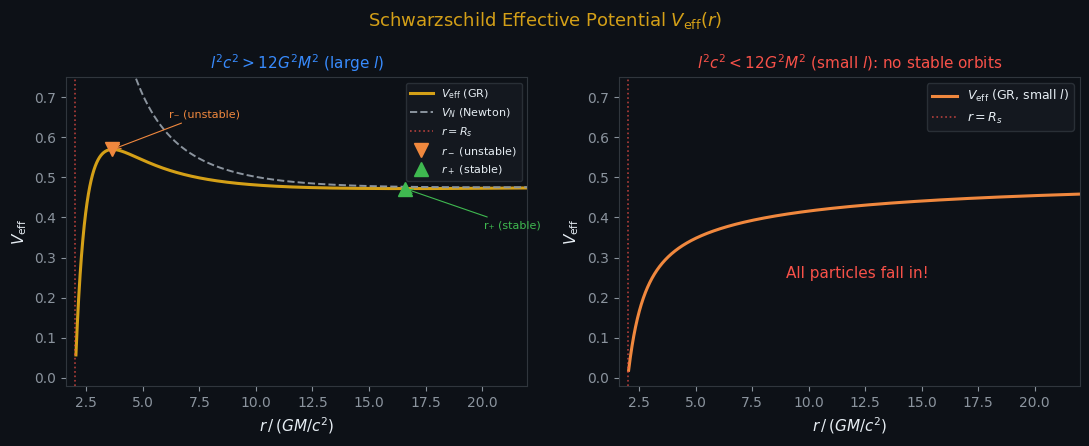

Fig 6 saved.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)
fig.suptitle('Schwarzschild Effective Potential $V_{\\mathrm{eff}}(r)$',
             color=GOLD, fontsize=13)

GM = 1.0; c = 1.0; Rs = 2*GM/c**2
r = np.linspace(Rs*1.02, 25, 3000)

def Veff(r, l):
    return 0.5*(c**2 + l**2/r**2)*(1 - Rs/r)

def VN(r, l):
    return -GM/r + l**2/(2*r**2) + 0.5*c**2

# Left: large l
ax = axes[0]
ax.set_facecolor(BG)
for sp in ax.spines.values(): sp.set_color(BORDER)
ax.tick_params(colors=MUTED)

l_large = 4.5
V = Veff(r, l_large)
VN_vals = VN(r, l_large)

ax.plot(r, V, color=GOLD, lw=2.2, label=r'$V_{\rm eff}$ (GR)')
ax.plot(r, VN_vals, color=MUTED, lw=1.4, ls='--', label=r'$V_N$ (Newton)')
ax.axvline(Rs, color=RED, lw=1.2, ls=':', alpha=0.7, label=r'$r=R_s$')

# Find critical points via sign change in derivative
dV = np.gradient(V, r)
sign_changes = np.where(np.diff(np.sign(dV)))[0]
if len(sign_changes) >= 2:
    # First sign change: + to - => local maximum => r_- (unstable)
    # Second sign change: - to + => local minimum => r_+ (stable)
    offsets = [(2.5, 0.08), (3.5, -0.10)]  # r_- → right+up, r_+ → right+down
    for sc, (marker, col, lbl), (dx, dy) in zip(sign_changes[:2],
        [('v', ORANGE, r'$r_-$ (unstable)'), ('^', GREEN, r'$r_+$ (stable)')],
        offsets):
        ax.plot(r[sc], V[sc], marker, color=col, ms=10, zorder=6, label=lbl)
        ax.annotate(lbl.replace('$','').replace('r_-','r₋').replace('r_+','r₊'),
                    xy=(r[sc], V[sc]), xytext=(r[sc]+dx, V[sc]+dy),
                    color=col, fontsize=8,
                    arrowprops=dict(arrowstyle='->', color=col, lw=0.8))

ax.set_xlim(Rs*0.8, 22)
ax.set_ylim(-0.02, 0.75)
ax.set_xlabel(r'$r\,/\,(GM/c^2)$', color=TEXT, fontsize=11)
ax.set_ylabel(r'$V_{\rm eff}$', color=TEXT, fontsize=11)
ax.set_title(r'$l^2c^2 > 12G^2M^2$ (large $l$)', color=BLUE, fontsize=11)
ax.legend(facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT, fontsize=8, loc='upper right')

# Right: small l
ax = axes[1]
ax.set_facecolor(BG)
for sp in ax.spines.values(): sp.set_color(BORDER)
ax.tick_params(colors=MUTED)

l_small = 2.0
V2 = Veff(r, l_small)
ax.plot(r, V2, color=ORANGE, lw=2.2, label=r'$V_{\rm eff}$ (GR, small $l$)')
ax.axvline(Rs, color=RED, lw=1.2, ls=':', alpha=0.7, label=r'$r=R_s$')
ax.set_xlim(Rs*0.8, 22)
ax.set_ylim(-0.02, 0.75)
ax.set_xlabel(r'$r\,/\,(GM/c^2)$', color=TEXT, fontsize=11)
ax.set_ylabel(r'$V_{\rm eff}$', color=TEXT, fontsize=11)
ax.set_title(r'$l^2c^2 < 12G^2M^2$ (small $l$): no stable orbits', color=RED, fontsize=11)
ax.text(9, 0.25, 'All particles fall in!', color=RED, fontsize=11)
ax.legend(facecolor=SURFACE, edgecolor=BORDER, labelcolor=TEXT, fontsize=9)

plt.tight_layout()
plt.savefig('figures/gr_fig06_effective_potential.png', **SAVE_KW)
plt.show()
print('Fig 6 saved.')


## Fig 7 — Perihelion Precession

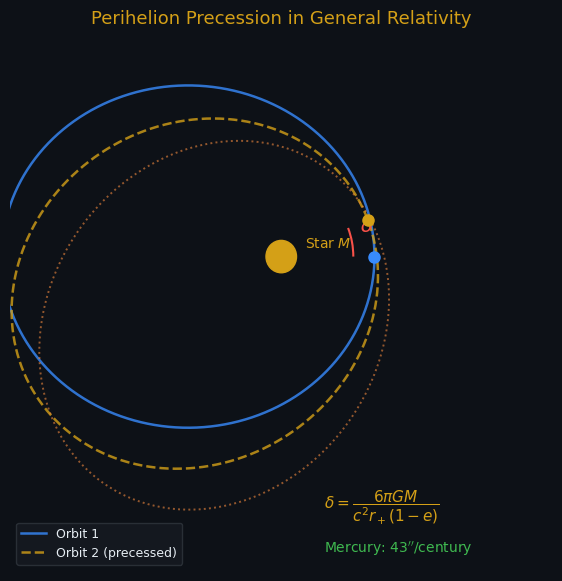

Fig 7 saved.


In [8]:
fig, ax = dark_fig(7, 7)
#ax.set_aspect('equal')
ax.set_xlim(-3.2, 3.2)
ax.set_ylim(-3.5, 2.5)
ax.axis('off')
ax.set_title('Perihelion Precession in General Relativity', fontsize=13)

# Star at centre
star = Circle((0, 0), 0.18, color=GOLD, zorder=10)
ax.add_patch(star)
ax.text(0.28, 0.1, 'Star $M$', color=GOLD, fontsize=10)

theta = np.linspace(0, 2*np.pi, 500)
a_orb, e_orb = 2.2, 0.5
b_orb = a_orb * np.sqrt(1 - e_orb**2)

x1 = a_orb*np.cos(theta) - a_orb*e_orb
y1 = b_orb*np.sin(theta)
ax.plot(x1, y1, color=BLUE, lw=1.8, alpha=0.8, label='Orbit 1')

delta = np.radians(22)
x2 = (a_orb*np.cos(theta) - a_orb*e_orb)*np.cos(delta) - b_orb*np.sin(theta)*np.sin(delta)
y2 = (a_orb*np.cos(theta) - a_orb*e_orb)*np.sin(delta) + b_orb*np.sin(theta)*np.cos(delta)
ax.plot(x2, y2, color=GOLD, lw=1.8, alpha=0.8, label='Orbit 2 (precessed)', ls='--')

delta2 = np.radians(44)
x3 = (a_orb*np.cos(theta) - a_orb*e_orb)*np.cos(delta2) - b_orb*np.sin(theta)*np.sin(delta2)
y3 = (a_orb*np.cos(theta) - a_orb*e_orb)*np.sin(delta2) + b_orb*np.sin(theta)*np.cos(delta2)
ax.plot(x3, y3, color=ORANGE, lw=1.4, alpha=0.6, ls=':')

peri1 = np.array([x1[0], y1[0]])
peri2 = np.array([x2[0], y2[0]])
ax.plot(*peri1, 'o', color=BLUE, ms=8, zorder=8)
ax.plot(*peri2, 'o', color=GOLD, ms=8, zorder=8)

arc_r = 0.85
arc = Arc((0,0), 2*arc_r, 2*arc_r, angle=0,
          theta1=np.degrees(np.arctan2(peri1[1], peri1[0])),
          theta2=np.degrees(np.arctan2(peri2[1], peri2[0])),
          color=RED, lw=1.5)
ax.add_patch(arc)
ax.text(arc_r*np.cos(np.radians(11))+0.1, arc_r*np.sin(np.radians(11))+0.12,
        r'$\delta$', color=RED, fontsize=14)

# Formula bottom-right (clear of orbits)
ax.text(0.5, -2.8,
        r'$\delta = \dfrac{6\pi GM}{c^2 r_+(1-e)}$',
        color=GOLD, fontsize=11, ha='left')
# Mercury result below formula
ax.text(0.5, -3.3,
        r'Mercury: $43^{\prime\prime}$/century',
        color=GREEN, fontsize=10, ha='left')

ax.legend(loc='lower left', facecolor=SURFACE, edgecolor=BORDER,
          labelcolor=TEXT, fontsize=9)

plt.savefig('figures/gr_fig07_perihelion.png', **SAVE_KW)
plt.show()
print('Fig 7 saved.')


## Fig 8 — Light Bending Geometry

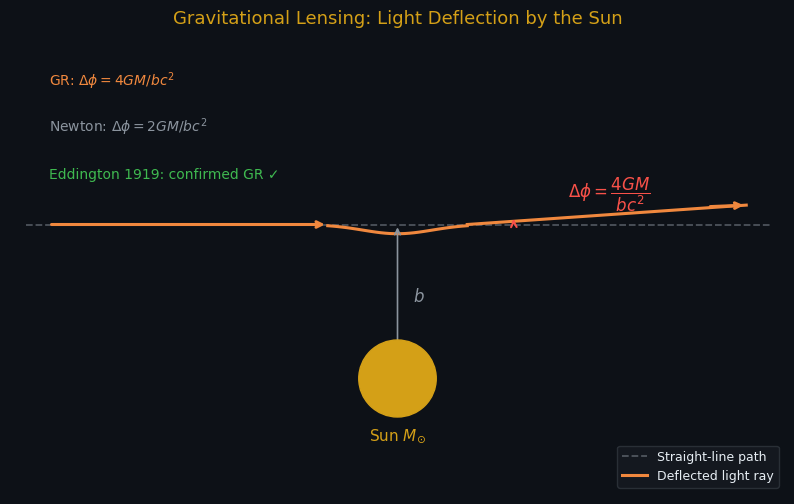

Fig 8 saved.

All figures saved to figures/


In [9]:
fig, ax = dark_fig(10, 6)
ax.set_xlim(-5, 5)
ax.set_ylim(-1.5, 4.5)
ax.axis('off')
ax.set_title('Gravitational Lensing: Light Deflection by the Sun', fontsize=13)

# Sun
sun = Circle((0, 0), 0.5, color=GOLD, zorder=8)
ax.add_patch(sun)
ax.text(0, -0.8, 'Sun $M_{\\odot}$', color=GOLD, ha='center', fontsize=11)

# Impact parameter b
b = 2.0
ax.annotate('', xy=(0, b), xytext=(0, 0),
            arrowprops=dict(arrowstyle='<->', color=MUTED, lw=1.2))
ax.text(0.2, b/2, '$b$', color=MUTED, fontsize=12)

# Undeflected ray (dashed)
ax.plot([-4.8, 4.8], [b, b], color=MUTED, lw=1.3, ls='--', alpha=0.5,
        label='Straight-line path')

# Deflected ray (curved near Sun)
# Approximate: straight coming in, bend near Sun, straight going out
delta_phi = 4  # degrees, exaggerated
delta_rad = np.radians(delta_phi)

# Incoming (left side): horizontal at height b
ax.annotate('', xy=(-0.9, b), xytext=(-4.5, b),
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.2))

# Outgoing (right side): slightly deflected
x_out = np.linspace(0.9, 4.5, 50)
y_out = b + np.tan(delta_rad) * (x_out - 0.9)
ax.plot(x_out, y_out, color=ORANGE, lw=2.2, label='Deflected light ray')
ax.annotate('', xy=(4.5, y_out[-1]), xytext=(4.0, y_out[-5]),
            arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.2))

# Smooth join near Sun (simple arc)
theta_bend = np.linspace(np.pi, np.pi - delta_rad, 30)
r_close = b / np.sin(np.pi/2)
x_bend = np.linspace(-0.9, 0.9, 30)
y_bend = b * np.ones(30)  # simplified horizontal for visual
# slight dip near Sun for visual effect
y_bend -= 0.12 * np.exp(-x_bend**2 / 0.4)
ax.plot(x_bend, y_bend, color=ORANGE, lw=2.2)

# Deflection angle arc
arc_r2 = 1.5
ax.annotate('', xy=(arc_r2*np.cos(np.radians(delta_phi)), b + arc_r2*np.sin(np.radians(delta_phi))),
            xytext=(arc_r2, b),
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.5))
ax.text(2.2, b+0.35, r'$\Delta\phi = \dfrac{4GM}{bc^2}$', color=RED, fontsize=12)

# Newtonian comparison
ax.text(-4.5, 3.8,
        r'GR: $\Delta\phi = 4GM/bc^2$',
        color=ORANGE, fontsize=10)
ax.text(-4.5, 3.2,
        r'Newton: $\Delta\phi = 2GM/bc^2$',
        color=MUTED, fontsize=10)
ax.text(-4.5, 2.6,
        r'Eddington 1919: confirmed GR ✓',
        color=GREEN, fontsize=10)

ax.legend(loc='lower right', facecolor=SURFACE, edgecolor=BORDER,
          labelcolor=TEXT, fontsize=9)

plt.savefig('figures/gr_fig08_light_bending.png', **SAVE_KW)
plt.show()
print('Fig 8 saved.')
print('\nAll figures saved to figures/')

In [10]:
# ── Download all figures as a zip file (Colab) ──────────────────────────────
import zipfile
import os

zip_path = 'gr_ch02_figures.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)  # store without 'figures/' prefix
            print(f'  Added: {fname}')

print(f'\nZip created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path) / 1024:.1f} KB')

# Download in Google Colab
try:
    from google.colab import files
    files.download(zip_path)
    print('Download started!')
except ImportError:
    print(f'Not running in Colab — file saved locally as: {zip_path}')


  Added: gr_fig01_newton_vs_gr.png
  Added: gr_fig02_geodesic_sphere.png
  Added: gr_fig03_equivalence_principle.png
  Added: gr_fig04_rindler.png
  Added: gr_fig05_time_dilation.png
  Added: gr_fig06_effective_potential.png
  Added: gr_fig07_perihelion.png
  Added: gr_fig08_light_bending.png

Zip created: gr_ch02_figures.zip
Size: 539.7 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
